# Lohoff Figure 2b recreation

Run TissueAgent from the supplied data and reference, with explicit final figures, validation, and a reproduction report. Complete run artifacts and execution state are retained under `cached/figure_recreation_lohoff-2b/`; this folder is ignored by Git. No prior run is deleted.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import shutil
import socket
import subprocess
import sys
from datetime import datetime, timezone

from IPython.display import Image, Markdown, display

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "pyproject.toml").exists():
    REPO_ROOT = REPO_ROOT.parent
assert (REPO_ROOT / "pyproject.toml").exists(), "Run from demo/ or the repository root."
TASK_NAME = "figure_recreation_lohoff-2b"
TASK_ID = "notebook_lohoff_2b_with_report"
MODEL = "gpt-5.5"
DATA_DIR = REPO_ROOT / "demo/data"
DATASETS = [DATA_DIR / "dataset_lohoff_et_al_seqfish.h5ad"]
REFERENCE = DATA_DIR / "reference_lohoff-2b.png"
ATTACHMENTS = [REFERENCE]
INPUTS = [*DATASETS, *ATTACHMENTS]
OUTPUT_DIR = REPO_ROOT / "cached" / TASK_NAME
PROMPT = "Recreate Lohoff Figure 2b from dataset_lohoff_et_al_seqfish.h5ad and reference_lohoff-2b.png. Draw all 19,416 cells at their original obsm['spatial'] positions, colored by the original obs['celltype_mapped_refined'] labels, with an inverted y-axis, cell-type legend, panel b label, scale annotation and A/P/D/V orientation as supported by the reference. Keep Low quality cells as gray background. Bind colors to the reference's labeled legend, reconciling case and spelling aliases explicitly; no color-map file is supplied. Do not invent observations for legend categories absent from the data. Reproduce the main panel b and legend; clipped fragments of adjacent panels at the lower left of the supplied capture are not additional data panels to recreate. Make all plotted cells and legend entries visible. The h5ad spatial coordinates lack physical-unit metadata, so any reference-derived scale annotation must be disclosed rather than claimed as independently calibrated. Export outputs/tables/plotted_data.csv with columns cell, x, y, celltype, preserving original observation IDs, coordinates, and labels (axis inversion is only a display setting). Save the accepted final figure as outputs/final_figure.png and outputs/final_figure.pdf, executable plotting/analysis code as outputs/plotting_code.py, a cell-type color mapping as outputs/tables/colormap.yaml, machine-readable analysis metadata as outputs/tables/analysis_metadata.json, and a detailed reproduction report as outputs/reports/reproduction_report.md. The report must describe input fields, exclusions and sample sizes, actual computations and seeds, approximations and missing inputs, visual comparison and unresolved differences. Inspect the final PNG against the reference. The final PNG must be the requested figure, never a diagnostic grid or comparison montage. Use only the supplied inputs; do not retrieve prior TissueAgent/baseline reproductions. Do not fabricate cells, genes, computed statistics, or labels, alter individual coordinates to match an image, or paste reference pixels into the result. Document colors estimated from the reference."
INPUT_RECORDS = []
for path in INPUTS:
    assert path.is_file(), f"Missing input: {path}"
    with path.open("rb") as stream:
        digest = hashlib.file_digest(stream, "sha256").hexdigest()
    role = "dataset" if path in DATASETS else "reference" if path == REFERENCE else "instructions"
    INPUT_RECORDS.append({"role": role, "path": str(path), "name": path.name, "sha256": digest})
print(json.dumps({"task": TASK_NAME, "model": MODEL, "inputs": INPUT_RECORDS,
                  "supplied_colormap": False, "output_dir": str(OUTPUT_DIR)}, indent=2))


{
  "task": "figure_recreation_lohoff-2b",
  "model": "gpt-5.5",
  "inputs": [
    {
      "role": "dataset",
      "path": "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/data/dataset_lohoff_et_al_seqfish.h5ad",
      "name": "dataset_lohoff_et_al_seqfish.h5ad",
      "sha256": "0588f810603cf3756a5a87d9730465a8968bb18f9c31d1b24e38f1d008305d70"
    },
    {
      "role": "reference",
      "path": "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/data/reference_lohoff-2b.png",
      "name": "reference_lohoff-2b.png",
      "sha256": "706fc81d878287454845583940f0213ce8a06e7fc61460692929a756562124ac"
    }
  ],
  "supplied_colormap": false,
  "output_dir": "/Users/wenduoc/new_TissueAgent/TissueAgent/cached/figure_recreation_lohoff-2b"
}


## Run the CLI

Set `OPENAI_API_KEY` in the notebook environment. A fresh run makes model calls; a completed local run is reused only if model, prompt, and input hashes match. Choose a new `OUTPUT_DIR` when changing settings or requesting another fresh run. Logs, state, intermediate attempts, final figures, and reports are retained under `cached/` rather than deleted.


In [2]:
manifest_path = OUTPUT_DIR / "run_manifest.json"
metrics_path = OUTPUT_DIR / "metrics.json"
if OUTPUT_DIR.is_dir() and manifest_path.is_file() and metrics_path.is_file():
    manifest = json.loads(manifest_path.read_text())
    metrics = json.loads(metrics_path.read_text())
    terminal_state = metrics.get("outcome", {}).get("terminal_state")
    expected_hashes = {record["name"]: record["sha256"] for record in INPUT_RECORDS}
    cached_hashes = {record["name"]: record["sha256"] for record in manifest["inputs"]}
    assert terminal_state == "completed" and manifest.get("cli_exit_code") == 0
    assert manifest.get("supplied_colormap") is False
    assert manifest.get("prompt") == PROMPT, "Prompt changed; choose a new OUTPUT_DIR."
    assert manifest.get("model") == MODEL, "Model changed; choose a new OUTPUT_DIR."
    assert cached_hashes == expected_hashes, "Inputs changed; choose a new OUTPUT_DIR."
    print(json.dumps({
        "terminal_state": terminal_state,
        "elapsed_seconds": manifest["elapsed_seconds"],
        "output_dir": str(OUTPUT_DIR),
        "reused_completed_output": True,
    }, indent=2))
else:
    if OUTPUT_DIR.exists():
        raise RuntimeError(f"{OUTPUT_DIR} already exists. Choose a new OUTPUT_DIR for a fresh run.")
    assert os.environ.get("OPENAI_API_KEY"), "Set OPENAI_API_KEY in the notebook environment for a fresh run."
    OUTPUT_DIR.mkdir(parents=True)
    STATE_ROOT = OUTPUT_DIR / "state"
    with socket.socket() as sock:
        sock.bind(("127.0.0.1", 0))
        gateway_port = sock.getsockname()[1]
    env = os.environ.copy()
    env.update({
        "TISSUEAGENT_STATE_ROOT": str(STATE_ROOT),
        "TISSUEAGENT_GATEWAY_PORT": str(gateway_port),
        "TISSUEAGENT_ORCHESTRATION_REASONING_EFFORT": "medium",
        "TISSUEAGENT_WORKER_REASONING_EFFORT": "high",
        "NUMBA_CACHE_DIR": str(OUTPUT_DIR / "cache/numba"),
        "MPLCONFIGDIR": str(OUTPUT_DIR / "cache/matplotlib"),
        "XDG_CACHE_HOME": str(OUTPUT_DIR / "cache/xdg"),
        "IPYTHONDIR": str(OUTPUT_DIR / "cache/ipython"),
        "JUPYTER_RUNTIME_DIR": str(OUTPUT_DIR / "cache/jupyter_runtime"),
        "PYTHONPATH": str(REPO_ROOT / "src") + os.pathsep + str(REPO_ROOT),
        "PATH": str(Path(sys.executable).parent) + os.pathsep + env.get("PATH", ""),
    })
    for key in ["NUMBA_CACHE_DIR", "MPLCONFIGDIR", "XDG_CACHE_HOME", "IPYTHONDIR", "JUPYTER_RUNTIME_DIR"]:
        Path(env[key]).mkdir(parents=True, exist_ok=True)
    command = [
        sys.executable, "-m", "cli", "--no-docker", "--json", "--model", MODEL,
        "--task-id", TASK_ID, "--seed", "0", "--attempt", "1",
        "--metrics-out", str(metrics_path),
    ]
    for dataset in DATASETS:
        command.extend(["--dataset", str(dataset)])
    for attachment in ATTACHMENTS:
        command.extend(["--attach", str(attachment)])
    command.append("-")

    transcript_path = OUTPUT_DIR / "transcript.log"
    (OUTPUT_DIR / "prompt.txt").write_text(PROMPT + "\n")
    started_at = datetime.now(timezone.utc)
    with transcript_path.open("w") as transcript:
        completed = subprocess.run(
            command, input=PROMPT, cwd=REPO_ROOT, env=env,
            stdout=transcript, stderr=subprocess.STDOUT, text=True, check=False,
        )
    finished_at = datetime.now(timezone.utc)
    project_dir = STATE_ROOT / "workspace/project"
    project_outputs = project_dir / "outputs"
    if project_outputs.is_dir():
        for source in project_outputs.iterdir():
            destination = OUTPUT_DIR / source.name
            if source.is_dir():
                shutil.copytree(source, destination, dirs_exist_ok=True)
            else:
                shutil.copy2(source, destination)
    if (project_dir / "metrics.json").is_file():
        shutil.copy2(project_dir / "metrics.json", OUTPUT_DIR / "project_metrics.json")
    if not metrics_path.is_file():
        raise RuntimeError(f"CLI exited {completed.returncode} without metrics. See {transcript_path}; state retained at {STATE_ROOT}.")
    metrics = json.loads(metrics_path.read_text())
    terminal_state = metrics.get("outcome", {}).get("terminal_state")
    manifest = {
        "task": TASK_NAME, "task_id": TASK_ID, "model": MODEL,
        "started_at_utc": started_at.isoformat(),
        "finished_at_utc": finished_at.isoformat(),
        "elapsed_seconds": metrics.get("run", {}).get("wall_time_s", (finished_at - started_at).total_seconds()),
        "elapsed_seconds_definition": "CLI-reported workflow wall time, falling back to subprocess wall time",
        "command": command, "prompt": PROMPT, "inputs": INPUT_RECORDS,
        "supplied_colormap": False, "cli_exit_code": completed.returncode,
        "terminal_state": terminal_state, "state_root": str(STATE_ROOT),
    }
    manifest_path.write_text(json.dumps(manifest, indent=2) + "\n")
    if completed.returncode != 0 or terminal_state != "completed":
        raise RuntimeError(f"CLI failed (exit={completed.returncode}, terminal_state={terminal_state}). See {transcript_path}; state retained at {STATE_ROOT}.")
    print(json.dumps({"terminal_state": terminal_state, "elapsed_seconds": manifest["elapsed_seconds"], "output_dir": str(OUTPUT_DIR)}, indent=2))


{
  "terminal_state": "completed",
  "elapsed_seconds": 1274.99,
  "output_dir": "/Users/wenduoc/new_TissueAgent/TissueAgent/cached/figure_recreation_lohoff-2b"
}


## Validate computed and plotted data


In [3]:
import anndata as ad
import numpy as np
import pandas as pd

plotted = pd.read_csv(OUTPUT_DIR / "tables/plotted_data.csv", dtype={"cell": str})
assert {"cell", "x", "y", "celltype"} <= set(plotted.columns)
adata = ad.read_h5ad(DATASETS[0], backed="r")
try:
    expected = pd.DataFrame(adata.obsm["spatial"], index=adata.obs_names.astype(str), columns=["x", "y"])
    expected["celltype"] = adata.obs["celltype_mapped_refined"].astype(str).to_numpy()
finally:
    adata.file.close()
expected = expected.sort_index()
actual = plotted.set_index("cell").sort_index()
assert len(actual) == 19416 and actual.index.is_unique and actual.index.equals(expected.index)
assert actual["celltype"].equals(expected["celltype"])
np.testing.assert_allclose(actual[["x", "y"]], expected[["x", "y"]], rtol=0, atol=1e-8)
print("Verified all 19,416 original cell IDs, labels, and spatial coordinates.")
display(actual.groupby("celltype").size().rename("Cells").to_frame())


Verified all 19,416 original cell IDs, labels, and spatial coordinates.


,Cells
celltype,
Allantois,77
Anterior somitic tissues,112
Cardiomyocytes,737
Cranial mesoderm,528
Definitive endoderm,213
Dermomyotome,523
Endothelium,953
Erythroid,300
Forebrain/Midbrain/Hindbrain,3704


## Final figure


cached/figure_recreation_lohoff-2b/final_figure.png


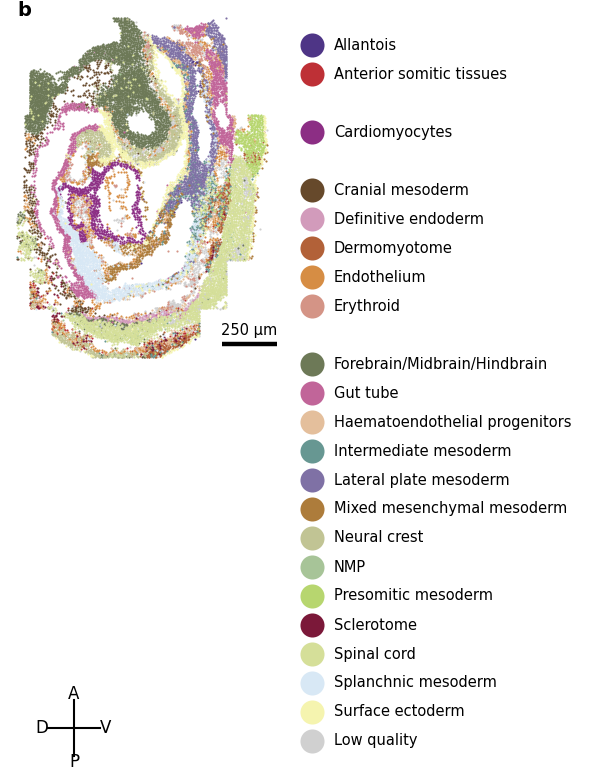

In [4]:
selected = OUTPUT_DIR / "final_figure.png"
for path in (selected, OUTPUT_DIR / "final_figure.pdf", OUTPUT_DIR / "plotting_code.py",
             OUTPUT_DIR / "tables/colormap.yaml", OUTPUT_DIR / "tables/analysis_metadata.json",
             OUTPUT_DIR / "reports/reproduction_report.md"):
    assert path.is_file(), f"Missing final artifact: {path}; inspect transcript.log."
print(selected.relative_to(REPO_ROOT))
display(Image(filename=str(selected)))


## Reproduction report


In [5]:
report_path = OUTPUT_DIR / "reports/reproduction_report.md"
print(report_path.relative_to(REPO_ROOT))
display(Markdown(report_path.read_text()))


cached/figure_recreation_lohoff-2b/reports/reproduction_report.md


# Lohoff Figure 2b reproduction report

## Inputs and target

- Dataset: `library/datasets/dataset_lohoff_et_al_seqfish.h5ad`.
- Reference image: `project/uploads/reference_lohoff-2b.png`.
- Reference capture size: 592 × 784 px.
- Target content interpreted as the main panel **b** spatial map plus its legend, panel label, scale annotation, and A/P/D/V orientation compass. The clipped lower-left fragments of adjacent panels in the supplied capture were not treated as additional data panels.

## Dataset fields used

- `adata.obsm['spatial']`: original two-dimensional spatial coordinates, shape `(19416, 2)`.
- `adata.obs['celltype_mapped_refined']`: original cell-type labels used for coloring.
- `adata.obs_names`: preserved as the `cell` column in `plotted_data.csv`.
- `adata.X` / genes: not used for this plotting-only recreation; `n_vars=351` was recorded for inventory only.

Spatial coordinate extents in the original data: x=[-2.54936823649, 2.52029370812], y=[-3.49208422942, 3.49208422942]. The y-axis inversion is a display setting only; exported coordinates are not inverted or otherwise altered.

## Sample sizes and exclusions

- Total observations in H5AD: 19416.
- Total observations plotted and exported: 19416.
- Observations excluded: 0.
- Low quality cells: 1645; plotted first as a gray background layer (`#d0d0d0`).
- Reference-only legend classes absent from the data and therefore not plotted or added to the final legend: Blood progenitors, Caudal mesoderm, ExE endoderm.

Category counts:

- Allantois: 77
- Anterior somitic tissues: 112
- Cardiomyocytes: 737
- Cranial mesoderm: 528
- Definitive endoderm: 213
- Dermomyotome: 523
- Endothelium: 953
- Erythroid: 300
- Forebrain/Midbrain/Hindbrain: 3704
- Gut tube: 1464
- Haematoendothelial progenitors: 637
- Intermediate mesoderm: 623
- Lateral plate mesoderm: 1243
- Low quality: 1645
- Mixed mesenchymal mesoderm: 541
- NMP: 109
- Neural crest: 912
- Presomitic mesoderm: 458
- Sclerotome: 78
- Spinal cord: 2620
- Splanchnic mesoderm: 1138
- Surface ectoderm: 801

## Color reconciliation and provenance

No user color-map file was supplied. Colors were estimated from the supplied reference legend using the `figure-reproduce` extraction/colormap workflow:

1. `extract_reference_spec.py` was run on the supplied reference with legend box `290,20,590,735`; output is `outputs/tables/reference_spec_final.json`.
2. `build_colormap.py` was used to measure legend swatches by label (`outputs/tables/colormap_skill_raw.yaml`), then the plotted palette was reconciled explicitly to include the data-only `Low quality` class as neutral gray and to exclude reference-only absent classes.
3. Final `outputs/tables/colormap.yaml` was written with the skill colormap writer and verified with `build_colormap.py --verify` (OK, provenance tier 3-legend, 22 categories).

Explicit alias reconciliation:

- Dataset `Forebrain/Midbrain/Hindbrain` ↔ reference `Forebrain/midbrain/hindbrain` (case alias).
- Dataset `Haematoendothelial progenitors` ↔ reference `Hematoendothelial progenitors` (spelling alias).
- Exact label matches were used for all other plotted non-low-quality categories.

Plotted color mapping:

- Allantois: `#4e3586`
- Anterior somitic tissues: `#be3036`
- Cardiomyocytes: `#8c2e84`
- Cranial mesoderm: `#66492b`
- Definitive endoderm: `#d29bbb`
- Dermomyotome: `#b26138`
- Endothelium: `#d68d44`
- Erythroid: `#d49486`
- Forebrain/Midbrain/Hindbrain: `#6d7957`
- Gut tube: `#c16599`
- Haematoendothelial progenitors: `#e4bf9c`
- Intermediate mesoderm: `#679792`
- Lateral plate mesoderm: `#7f71a5`
- Low quality: `#d0d0d0`
- Mixed mesenchymal mesoderm: `#ad7c3b`
- Neural crest: `#c1c494`
- NMP: `#a7c498`
- Presomitic mesoderm: `#b7d66f`
- Sclerotome: `#7b1839`
- Spinal cord: `#d5df99`
- Splanchnic mesoderm: `#d8e8f5`
- Surface ectoderm: `#f5f4af`

The colors are estimates from a raster legend. They should not be interpreted as an author-supplied palette file.

## Rendering computations and parameters

- Code: `outputs/plotting_code.py`.
- Accepted render attempt: 5; final files were copied byte-for-byte from `outputs/figures/lohoff_2b_attempt5.png/.pdf` to `outputs/final_figure.png/.pdf`.
- Canvas: 592 × 784 px at 100 dpi, white background.
- Spatial coordinates were linearly mapped into a reference-matched map box: left=17 px, top=18 px, width=250 px, height=339 px.
- Matplotlib scatter markers: filled circles, size 2.4 points², no outlines. Low quality cells are drawn first; other cell types are drawn afterward in dataset category order.
- Axis display: image-coordinate axes with inverted y direction to match the reference; this does not change `plotted_data.csv`.
- Panel label: `b` at the upper left.
- Scale annotation: `250 μm`, visually matched to the reference capture. The H5AD spatial coordinates lack physical-unit metadata, so this is reference-derived and not independently calibrated.
- Orientation annotation: A/P/D/V compass included because it is visible in the supplied reference.
- Random seeds: none. No stochastic computation was used.

## Output data integrity checks

`outputs/tables/plotted_data.csv` has columns `cell,x,y,celltype`, 19416 rows, original observation IDs in original order, original `obsm['spatial']` coordinates (within numeric CSV precision), and original `obs['celltype_mapped_refined']` labels. `outputs/tables/analysis_metadata.json` records the same checks in machine-readable form.

## Verification and visual comparison

The final PNG was opened after finalization and confirmed to be the requested single figure, not a comparison montage. Comparison artifacts are separate:

- Skill comparison montage: `outputs/figures/compare_figures_attempt5.png`.
- Skill geometry comparison: `outputs/figures/compare_figures_geometry_attempt5.png`.
- Enhanced pixel-difference image: `outputs/figures/compare_diff.png`.
- Final metrics JSON: `outputs/tables/compare_metrics.json`.

Metric trajectory:

- Attempt 1: SSIM 0.6605, pHash 4, ORB 160, palette dE 15.26, geometry_clean=False, b_levels={'ssim': 'B2', 'color': 'B3', 'text': 'B3', 'geometry': 'B2', 'combined': 'B2', 'limited_by': 'geometry+ssim'}
- Attempt 2: SSIM 0.6772, pHash 4, ORB 166, palette dE 15.26, geometry_clean=False, b_levels={'ssim': 'B2', 'color': 'B3', 'text': 'B3', 'geometry': 'B2', 'combined': 'B2', 'limited_by': 'geometry+ssim'}
- Attempt 3: SSIM 0.6927, pHash 4, ORB 164, palette dE 15.26, geometry_clean=False, b_levels={'ssim': 'B2', 'color': 'B3', 'text': 'B3', 'geometry': 'B2', 'combined': 'B2', 'limited_by': 'geometry+ssim'}
- Attempt 4: SSIM 0.7746, pHash 4, ORB 162, palette dE 15.26, geometry_clean=False, b_levels={'ssim': 'B3', 'color': 'B3', 'text': 'B3', 'geometry': 'B2', 'combined': 'B2', 'limited_by': 'geometry'}
- Attempt 5: SSIM 0.7745, pHash 4, ORB 165, palette dE 15.04, geometry_clean=False, b_levels={'ssim': 'B3', 'color': 'B3', 'text': 'B3', 'geometry': 'B2', 'combined': 'B2', 'limited_by': 'geometry'}

Final automated metrics: SSIM=0.7745, pHash Hamming=4, ORB good matches=165, palette mean ΔE=15.04, b-levels={'ssim': 'B3', 'color': 'B3', 'text': 'B3', 'geometry': 'B2', 'combined': 'B2', 'limited_by': 'geometry'}.

Automated comparison findings for the accepted attempt:

- PALETTE: mean colour distance to the target is dE 15.0 (<2.3 is imperceptible) -- the categories are drawn in the wrong colours. Resolve the palette from the reference legend (`build_colormap.py --reference <fig> --legend-box x0,y0,x1,y1`) rather than a default, then re-render.

Visual inspection summary:

- The spatial shape, orientation, panel label, scale annotation, and A/P/D/V compass visually match the reference-supported panel elements.
- All plotted cells are visible; Low quality cells form a gray underlay/background as requested.
- The legend contains only categories present in the data plus Low quality, so it intentionally omits Blood progenitors, Caudal mesoderm, and ExE endoderm rather than inventing observations.
- The final legend labels preserve original dataset spelling/case, so two entries differ typographically from the reference legend after alias reconciliation (`Forebrain/Midbrain/Hindbrain` vs `Forebrain/midbrain/hindbrain`; `Haematoendothelial` vs `Hematoendothelial`). This was retained to satisfy preservation of original labels.
- The lower-left clipped fragments visible in the reference capture are not recreated, following the instruction that they are not additional data panels.
- The automated palette warning is retained in the metrics because the comparison script uses image-level dominant-color matching and is not label-aware; the plotted colors themselves are bound to the measured reference legend swatches in `colormap.yaml`.

## Approximations, missing inputs, and unresolved differences

- No physical-unit spatial scale metadata is present in the H5AD; the `250 μm` scale bar is a reference-derived visual annotation only.
- Marker size, exact map box, legend offsets, and compass placement were matched visually to the raster reference rather than recovered from plotting source code.
- Reference colors were estimated from a raster legend; compression/anti-aliasing can cause small color differences.
- Reference-only categories absent from the data necessarily remain absent from the plotted data and final legend.
- The reference crop contains neighboring-panel fragments at lower left that were intentionally not reproduced.
